# 10 · Linear attention, RetNet & RWKV — "Transformers are RNNs"

Softmax attention needs the full T×T score matrix. If we replace `softmax(QKᵀ)` by a **kernel** `φ(Q)φ(K)ᵀ` (or a
decayed `QKᵀ ⊙ D`), the sum can be re-associated: `φ(Q)(φ(K)ᵀV)`. That gives two equivalent forms:

* **parallel form** – train like a Transformer (matrix multiplies),
* **recurrent form** – infer like an RNN with a fixed-size state `S_t = γ S_{t-1} + k_tᵀ v_t`, `o_t = q_t S_t`.

We implement three members of the family and *prove numerically* that parallel ≡ recurrent.

---

### At a glance

| | |
|---|---|
| **Family** | Linear attention · retention · RWKV |
| **Representative models** | Linear Transformer, RetNet, RWKV, GLA |
| **Core idea** | Replace softmax attention by a decayed kernel so it can run both in parallel (training) and recurrently (inference). |
| **Compute / memory** | O(T) recurrent inference, O(1) state |
| **Dataset** | tiny-Shakespeare (char level) – see notebook 00 |
| **Runtime** | ≈ 179 s on a laptop CPU |

### What you will learn

- Prove parallel ≡ recurrent form numerically
- Implement retention and RWKV time-mixing
- Inspect learned memory decay

### Contents

1. [Train RetNet-style and RWKV-style language models](#1-%C2%B7-Train-RetNet-style-and-RWKV-style-language-models)
2. [What did they learn about memory?](#2-%C2%B7-What-did-they-learn-about-memory%3F)

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np
from llmarch import *
setup_style()
from llmarch.blocks import *
set_seed(0); device = get_device(); STEPS = 1000
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]

## 1 · Linear attention (φ = elu+1)

In [2]:
def linattn_parallel(q, k, v):                      # q,k,v: (B,T,d)
    q, k = F.elu(q) + 1, F.elu(k) + 1
    A = (q @ k.transpose(-1, -2)).tril()            # (B,T,T) no softmax, just a causal kernel
    return (A @ v) / (A.sum(-1, keepdim=True) + 1e-6)

def linattn_recurrent(q, k, v):
    q, k = F.elu(q) + 1, F.elu(k) + 1; B, T, d = q.shape
    S = q.new_zeros(B, d, v.size(-1)); z = q.new_zeros(B, d); out = []
    for t in range(T):
        S = S + k[:, t, :, None] * v[:, t, None, :]          # state: running sum of k^T v   (d × d, fixed size!)
        z = z + k[:, t]                                      # running normaliser
        out.append((q[:, t, None, :] @ S).squeeze(1) / ((q[:, t] * z).sum(-1, keepdim=True) + 1e-6))
    return torch.stack(out, 1)
q, k, v = [torch.randn(2, 20, 8) for _ in range(3)]
print("linear attention, parallel == recurrent:", torch.allclose(linattn_parallel(q, k, v), linattn_recurrent(q, k, v), atol=1e-5))

linear attention, parallel == recurrent: True


## 2 · RetNet "retention": add exponential decay γ
`D[i,j] = γ^(i−j)` for `i ≥ j`: recent tokens count more. Each head gets its own γ (multi-scale memory).

retention, parallel == recurrent: True


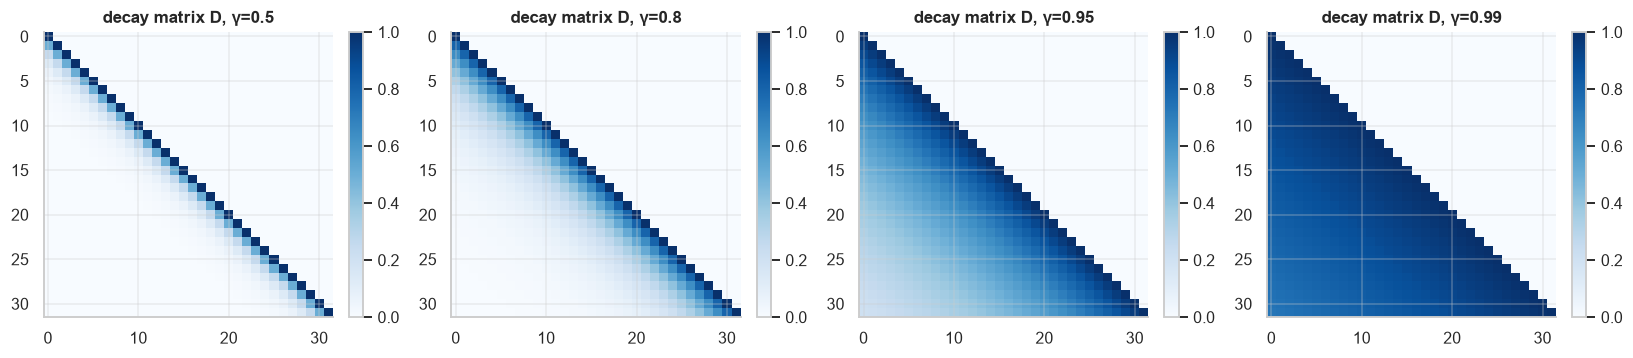

In [3]:
def decay_matrix(gamma, T):
    i = torch.arange(T)[:, None]; j = torch.arange(T)[None, :]
    return torch.where(i >= j, gamma ** (i - j).float(), torch.zeros(()))
def retention_parallel(q, k, v, gamma):
    T = q.size(1); return ((q @ k.transpose(-1, -2)) * decay_matrix(gamma, T).to(q.device)) @ v
def retention_recurrent(q, k, v, gamma):
    B, T, d = q.shape; S = q.new_zeros(B, d, v.size(-1)); out = []
    for t in range(T):
        S = gamma * S + k[:, t, :, None] * v[:, t, None, :]; out.append((q[:, t, None, :] @ S).squeeze(1))
    return torch.stack(out, 1)
print("retention, parallel == recurrent:", torch.allclose(retention_parallel(q, k, v, 0.9), retention_recurrent(q, k, v, 0.9), atol=1e-4))
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, g in zip(axs, [0.5, 0.8, 0.95, 0.99]): plot_heatmap(decay_matrix(g, 32), title=f"decay matrix D, γ={g}", ax=ax, cmap="Blues")
plt.tight_layout(); plt.show()

## 3 · RWKV time-mixing (WKV)
Channel-wise decaying average of past values, with a "bonus" `u` for the current token:
`wkv_t = (Σ_{i<t} e^{-(t-1-i)w + k_i} v_i + e^{u+k_t} v_t) / (Σ_{i<t} e^{-(t-1-i)w + k_i} + e^{u+k_t})`.
Runs as an RNN with two running sums (numerator `a`, denominator `b`).

In [4]:
class RWKVTimeMix(nn.Module):
    def __init__(s, d):
        super().__init__(); s.mix = nn.Parameter(torch.full((3, d), .5)); s.wr, s.wk, s.wv = [nn.Linear(d, d, bias=False) for _ in range(3)]
        s.wo = nn.Linear(d, d, bias=False); s.w = nn.Parameter(torch.randn(d) * .3 - 1.0); s.u = nn.Parameter(torch.zeros(d)); s.last_decay = None
    def forward(s, x):
        xs = F.pad(x, (0, 0, 1, -1))                                   # token shift: previous token's features
        xr, xk, xv = [x * m + xs * (1 - m) for m in s.mix]
        r, k, v = torch.sigmoid(s.wr(xr)), s.wk(xk).clamp(max=10), s.wv(xv); w = F.softplus(s.w)    # w > 0 -> decay e^{-w} < 1
        B, T, D = x.shape; a = x.new_zeros(B, D); b = x.new_zeros(B, D); out = []
        for t in range(T):
            e_u = torch.exp(s.u + k[:, t]); out.append((a + e_u * v[:, t]) / (b + e_u + 1e-6))
            a = torch.exp(-w) * a + torch.exp(k[:, t]) * v[:, t]; b = torch.exp(-w) * b + torch.exp(k[:, t])
        s.last_decay = torch.exp(-w).detach()
        return s.wo(r * torch.stack(out, 1))
class RWKVChannelMix(nn.Module):       # squared-ReLU FFN with receptance gate
    def __init__(s, d):
        super().__init__(); s.mix = nn.Parameter(torch.full((2, d), .5)); s.wk = nn.Linear(d, 3 * d, bias=False); s.wv = nn.Linear(3 * d, d, bias=False); s.wr = nn.Linear(d, d, bias=False)
    def forward(s, x):
        xs = F.pad(x, (0, 0, 1, -1)); xk, xr = [x * m + xs * (1 - m) for m in s.mix]
        return torch.sigmoid(s.wr(xr)) * s.wv(F.relu(s.wk(xk)) ** 2)
class RetentionMixer(nn.Module):
    """Multi-head retention with a different gamma per head (RetNet), parallel form for training."""
    def __init__(s, d, h):
        super().__init__(); s.h, s.hd = h, d // h; s.qkv = nn.Linear(d, 3 * d, bias=False); s.o = nn.Linear(d, d, bias=False); s.gn = RMSNorm(s.hd)
        s.register_buffer("gamma", 1 - 2.0 ** (-5 - torch.arange(h).float()))
    def forward(s, x):
        B, T, D = x.shape; q, k, v = [t.view(B, T, s.h, s.hd).transpose(1, 2) for t in s.qkv(x).chunk(3, -1)]
        q = q * s.hd ** -0.5; i = torch.arange(T, device=x.device); dist = (i[:, None] - i[None]).float()
        Dm = torch.where(dist >= 0, s.gamma[:, None, None] ** dist.clamp(min=0), torch.zeros((), device=x.device))
        y = ((q @ k.transpose(-1, -2)) * Dm) @ v
        return s.o(s.gn(y).transpose(1, 2).reshape(B, T, D))

## 1 · Train RetNet-style and RWKV-style language models

== RetNet (retention + SwiGLU) 338,760 params


== RWKV (time-mix + channel-mix) 313,056 params


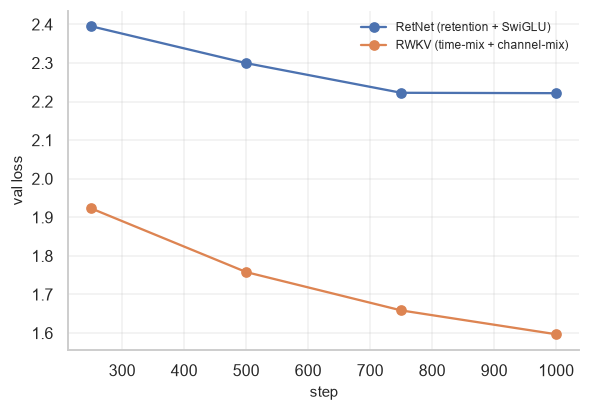


By the busin and his gracious to the sea;
To have being that stitle as would to the best
To more the day and she his charge, interceibness subject,
It we here a subject to heaven me an here,
Which sposs, if your can threach some me to mine asse a tim


In [5]:
d = 96
nets = {
    "RetNet (retention + SwiGLU)": lambda: DecoderLM(V, d, [Block(d, RetentionMixer(d, 4), SwiGLU(d)) for _ in range(3)]),
    "RWKV (time-mix + channel-mix)": lambda: DecoderLM(V, d, [Block(d, RWKVTimeMix(d), RWKVChannelMix(d)) for _ in range(3)]),
}
models, hists = {}, {}
for n, f in nets.items():
    set_seed(0); models[n] = f(); print("==", n, f"{count_params(models[n]):,} params")
    hists[n] = train_lm(models[n], train, val, steps=STEPS, block_size=64, batch_size=32, lr=3e-3, device=device, eval_every=250, verbose=False)
save_result("10 RetNet (retention)", models["RetNet (retention + SwiGLU)"], hists["RetNet (retention + SwiGLU)"])
save_result("10 RWKV", models["RWKV (time-mix + channel-mix)"], hists["RWKV (time-mix + channel-mix)"])
plt.figure(figsize=(6, 4))
for n, h in hists.items(): plt.plot(h["val_step"], h["val"], "o-", label=n)
plt.legend(fontsize=8); plt.xlabel("step"); plt.ylabel("val loss"); plt.grid(alpha=.3); plt.show()
start = torch.zeros((1, 1), dtype=torch.long, device=device)
print(data["decode"](generate(models["RWKV (time-mix + channel-mix)"], start, 250, temperature=.8, top_k=10, block_size=128)[0].tolist()))

## 2 · What did they learn about memory?
* RetNet: per-head γ is *fixed* (1−2⁻⁵ … 1−2⁻⁸): short- to long-range heads.
* RWKV: per-channel decay `e^{−w}` is *learned*: a spectrum of fast and slow channels.

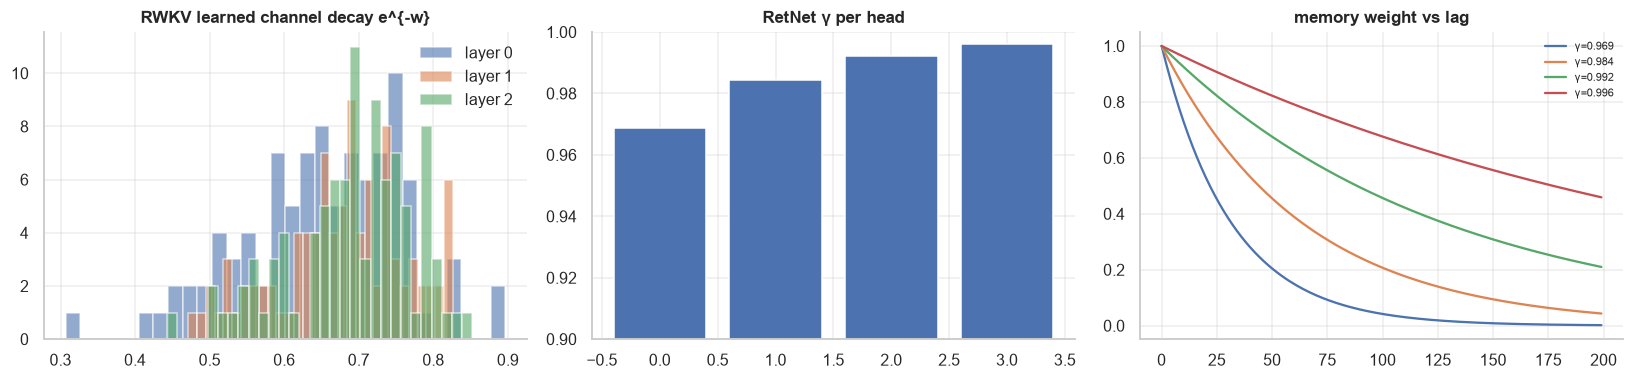

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for l in range(3): ax[0].hist(models["RWKV (time-mix + channel-mix)"].blocks[l].mixer.last_decay.cpu().numpy(), bins=30, alpha=.6, label=f"layer {l}")
ax[0].set_title("RWKV learned channel decay e^{-w}"); ax[0].legend()
g = models["RetNet (retention + SwiGLU)"].blocks[0].mixer.gamma.cpu(); ax[1].bar(range(4), g); ax[1].set_ylim(.9, 1); ax[1].set_title("RetNet γ per head")
lags = np.arange(0, 200); [ax[2].plot(lags, float(gi) ** lags, label=f"γ={float(gi):.3f}") for gi in g]; ax[2].set_title("memory weight vs lag"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

---

## Key takeaways

- Dropping the softmax lets you re-associate (QKᵀ)V as Q(KᵀV): a fixed-size state.
- Exponential decay gives the state a controllable forgetting curve (per head in RetNet, per channel in RWKV).
- Fixed state ⇒ limited exact recall, which motivates hybrids.

## References

- [Katharopoulos et al., *Transformers are RNNs* (2020)](https://arxiv.org/abs/2006.16236)
- [Sun et al., *RetNet* (2023)](https://arxiv.org/abs/2307.08621)
- [Peng et al., *RWKV* (2023)](https://arxiv.org/abs/2305.13048)

---
*← previous: `09_state_space_mamba`  ·  next: `11_hybrid_jamba` →*